[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/15_Smart_Grid_Power_System_Attacks/QAE_SmartGridAnomaly_Cirillo2025.ipynb)

# Stacked quantum autoencoders (QCNN + QRNN) for smart-grid cyberattack detection: Cirillo and Esposito 2025 step by step

**Paper.** Franco Cirillo and Christian Esposito, *Quantum Autoencoder-Based Anomaly Detection for Cyberattacks in Smart Power Systems*, AIQxQIA 2025 (International Workshop on AI for Quantum and Quantum for AI, co-located with ECAI 2025), CEUR Workshop Proceedings vol. 4153, short paper 3. URL: <https://ceur-ws.org/Vol-4153/short3.pdf>. The authors state that the work translates the classical stacked CNN-/RNN-sparse-autoencoder of D'Angelo and Palmieri (Int. J. Intelligent Systems 36, 2021) into a quantum counterpart and that it is a proof of concept.

**What this notebook does.** It downloads the public Mississippi State University / Oak Ridge National Laboratory power-system attack dataset (the same data that the paper takes from Kaggle), applies the paper's preprocessing (2,000 random rows, `log1p` of skewed columns, clipping, mean imputation, 80/20 split, standard scaling, PCA keeping 95 % of the variance, min-max scaling to [0, 1], blocks of 4 features), builds the two quantum autoencoder stages with PennyLane (a 4-qubit, 6-layer quantum-convolutional encoder followed by a quantum-recurrent encoder/decoder), trains a hybrid quantum-classical classifier and a fully classical classifier with the paper's learning rates, and redraws the paper's only result figure (Figure 1: test accuracy and test loss per epoch). It then checks every claim of the paper that can be checked and adds the sanity baselines the paper does not report (majority class, random forest, RBF-SVM on the same four features and on all features).

**How to run.** Colab: *Runtime > Change runtime type > CPU*, then *Runtime > Run all*. The committed outputs are from `FAST_MODE = False` (5 seeds x 40 epochs, plus the all-blocks extension with 3 seeds x 20 epochs; about 80 minutes on a shared laptop CPU with 2 threads). `FAST_MODE = True` is the class demo (3 seeds x 15 epochs; about 8 minutes of notebook time, 11 minutes including imports, on the same shared machine). A session restart may be needed after the install cell. No GPU, no IBM account and no API key are needed; everything is simulated (PennyLane `default.qubit`, exact statevectors).

**What you get at the end.** The dataset exploration (shapes, labels, class bars, labelled 2-D projections of real rows), drawings of the two circuits that are executed, training curves for the hybrid and the classical classifier averaged over seeds, a table that puts the paper's numbers next to the notebook's with a verdict per claim, a critical reading and five exercises.

## The paper in one page

**Problem.** Cyberattacks on interconnected power-control systems (remote tripping command injection, relay-setting changes, false data injection) must be told apart from natural disturbances and normal operation. The authors ask whether a *stacked quantum autoencoder* can replace the classical stacked CNN-SAE + RNN-SAE detector of D'Angelo and Palmieri.

**Decision.** Attack / no attack (the classical model ends in a softmax that "indicates the presence or absence of a cyberattack").

**Data.** Mississippi State University / Oak Ridge National Laboratory power-system dataset (Kaggle copy, "Power system" by B. Barika): 37 simulated scenarios, 128 measurement columns (PMU phasors, relay, control panel and Snort log features), released as binary, three-class and multiclass files.

**Preprocessing (Section 4.1).** Random sample of 2,000 rows; `log1p` on highly skewed or very large columns; outliers clipped at an upper threshold; missing values imputed with the column mean; 80/20 train/test split; `StandardScaler`; PCA keeping at least 95 % of the variance; `MinMaxScaler` to [0, 1]; the result is cut into blocks of 4 features.

**Model (Sections 4.2 to 4.4).**
1. *QAE with QCNN* : 4 qubits, 6 layers; classical values enter by `RY` rotations, then random layers of rotations and CNOTs; each qubit is measured in the Pauli-Z basis giving four numbers; the "decoder" is the symbolic map `1 - measurement`.
2. *QAE with QRNN* : `AngleEmbedding` with `RY`; encoder = `RX`, `RY`, `RZ` on each qubit then CNOTs between adjacent qubits only; decoder = another set of `RX`, `RY`, `RZ`.
3. The reconstructed outputs feed a classifier. Two classifiers are compared: hybrid quantum-classical (with the stacked QAEs) and fully classical. Learning rate 1e-3 for quantum models and 1e-2 for classical ones, Adam, mini-batches, `CrossEntropyLoss` (+ `MSELoss` for the QAE reconstruction in the quantum model).

**Claims (Section 4.5, Figure 1, Conclusion).**
* C1. Both classifiers converge to a test accuracy of about 72 %.
* C2. With only four input features and 2,000 samples the quantum-enhanced model is competitive: comparable to or better than the classical baseline.
* C3. The quantum model's test loss decreases consistently over the epochs.
* C4. The classical model's test loss starts lower but is unstable and degrades over time.
* C5. The quantum model is more stable in the later epochs (steady improvement trend).

## What follows the paper and what had to be chosen

The paper is a four-page proof of concept and omits many details. Every choice below is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | Kaggle "Power system" (B. Barika), MSU/ORNL data, binary / three-class / multiclass versions | The original release of the same data from the maintainer's UAH site (Internet Archive copy, SHA-256 checked): the 15-file **binary** variant (Natural vs Attack, 78,368 rows after removing exact duplicates). The three-class release is used for the exploration plots only. The paper does not say which version it used; binary is chosen because the classifier outputs "attack or no attack". |
| Sample | random 2,000 rows | random 2,000 rows (seeded, not stratified); exact duplicates removed first (`# CHOICE:`) |
| `log1p` columns | "highly skewed or extremely large" | train-split columns with absolute skewness > 2 or maximum absolute value > 1e6; sign-preserving `sign(x) log1p(abs(x))` because phasor angles are negative (`# CHOICE:`) |
| Clipping | "clipped at an upper threshold" | upper clip at the 99th percentile of the training split (`# CHOICE:`) |
| Imputation | column mean | column mean of the training split; infinite impedances are first turned into NaN (`# CHOICE:`) |
| Split | 80/20 | stratified 80/20, `random_state=SEED`. All transforms are fitted on the training part only (the paper fits before splitting or does not say) |
| PCA / scaling | 95 % variance, then min-max to [0, 1] | same; test values are clipped to [0, 1] |
| Blocks | blocks of 4 features; the input is "only four features" | main experiment: the **first block** (the 4 leading principal components). A second experiment applies the same circuits to every block and concatenates (`# CHOICE:`). Incomplete trailing blocks are dropped |
| QCNN encoder | 4 qubits, 6 layers, RY loading, random layers of rotations and CNOTs, Pauli-Z read-out, decoder `1 - z` | `AngleEmbedding(pi * x, rotation="Y")` then `qml.RandomLayers` with 6 layers, 4 rotations per layer, seeded; the weights are random and **fixed** (not trained), as in a quanvolutional filter (`# CHOICE:` the paper does not say whether they are trained) |
| QRNN | AngleEmbedding RY, RX/RY/RZ + adjacent CNOTs, mirrored RX/RY/RZ decoder | exactly that on 4 qubits; angles `pi * (1 - z) / 2` so that the decoded QCNN values lie in [0, pi]; trainable; reconstruction `(1 - z_out) / 2` compared with the input block by `MSELoss` (`# CHOICE:`) |
| Classifier head | not described | `Linear(4, 16) - ReLU - Linear(16, 2)` for both models, applied to the QAE reconstruction (hybrid) or to the raw block (classical) (`# CHOICE:`) |
| Optimiser / loss | Adam; lr 1e-3 (quantum), 1e-2 (classical); CrossEntropy (+ MSE for the QAE) | the same; batch size 32, number of epochs `EPOCHS` (not given in the paper), MSE weight 1 |
| Seeds | not stated (apparently one run) | `N_SEEDS` model seeds on one fixed data split; mean +/- std and a binomial 95 % interval for the test accuracy |
| Hardware | simulator | PennyLane `default.qubit` (exact statevectors) |
| Baselines the paper lacks | none | majority class, random forest and RBF-SVM on the same 4 features and on all PCA components / all raw features |

In [1]:
# Install (pinned to the versions tested for this notebook). Colab already ships numpy, pandas, scikit-learn, scipy,
# matplotlib and torch. The guard avoids re-installing on a machine that already has the packages.
import os, sys, subprocess, importlib
N_THREADS = int(os.environ.get("QC193_THREADS", "2"))      # on a busy shared machine set QC193_THREADS=1
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, str(N_THREADS))
IN_COLAB = "google.colab" in sys.modules

def _missing():
    for m in ("pennylane", "py7zr", "torch", "sklearn", "scipy", "requests"):
        try:
            importlib.import_module(m)
        except Exception:
            return True
    return False

if IN_COLAB or _missing():
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "py7zr", "requests"])
    print("Installed. If Colab complains about numpy, use Runtime > Restart session and run again.")
else:
    print("All packages already available; skipping install.")

All packages already available; skipping install.


## 1. Configuration

Every tunable constant is here. `FAST_MODE = True` is the class demo; `FAST_MODE = False` uses more epochs and seeds and also runs the all-blocks experiment with more seeds. The paper does not report its number of epochs or seeds.

In [2]:
import os
from pathlib import Path

FAST_MODE = False                  # True: class demo (a few minutes). False: larger budgets (see below).
SEED = 42                         # global seed (data sample, split, circuit randomness, model initialisation base)
N_QUBITS = 4                      # the paper: 4 qubits, blocks of 4 features
SAMPLE_N = 2000                   # paper: random sample of 2,000 rows
TEST_SIZE = 0.20                  # paper: 80/20 split
PCA_VARIANCE = 0.95               # paper: PCA keeps at least 95 % of the variance
QCNN_LAYERS = 6                   # paper: 6-layer QCNN encoder
SKEW_T, BIG_T, CLIP_Q = 2.0, 1e6, 99.0    # CHOICE: thresholds for log1p columns and the upper clipping percentile
LR_QUANTUM, LR_CLASSICAL = 1e-3, 1e-2     # paper: learning rates of the quantum and classical models
BATCH = 32                        # CHOICE: not given in the paper
HIDDEN = 16                       # CHOICE: width of the classifier head
MSE_WEIGHT = 1.0                  # CHOICE: weight of the QAE reconstruction loss
DATA_DIR = Path(os.environ.get("QC193_DATA_DIR", "qc193_data"))   # downloaded archives are cached here
IBM_TOKEN = ""                    # unused: everything is simulated

# budgets that depend on FAST_MODE (the paper does not report epochs or seeds)
EPOCHS        = 15 if FAST_MODE else 40       # epochs of the main experiment (first block, 4 features)
N_SEEDS       = 3  if FAST_MODE else 5        # model seeds of the main experiment
EPOCHS_ALL    = 6  if FAST_MODE else 20       # epochs of the all-blocks experiment
N_SEEDS_ALL   = 1  if FAST_MODE else 3        # model seeds of the all-blocks experiment
print(f"FAST_MODE={FAST_MODE}  EPOCHS={EPOCHS}  N_SEEDS={N_SEEDS}  EPOCHS_ALL={EPOCHS_ALL}  N_SEEDS_ALL={N_SEEDS_ALL}")

FAST_MODE=False  EPOCHS=40  N_SEEDS=5  EPOCHS_ALL=20  N_SEEDS_ALL=3


In [3]:
import time, math, random, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy, sklearn
import torch
import torch.nn as nn
import pennylane as qml
import requests
from scipy.stats import skew
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(N_THREADS)
rng_global = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
T0 = time.time()
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__,
      "| torch", torch.__version__, "| pennylane", qml.__version__)

# Hugging Face token handling (required by the repository's rules). This dataset is NOT on Hugging Face and is not gated,
# so the token is never used here. If you point the download at a gated mirror, put your own token into Colab Secrets
# as HF_TOKEN; never paste it into the notebook.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1 | torch 2.14.1+cpu | pennylane 0.45.1


## 2. Data: download, verify, pool, clean

The Mississippi State University / Oak Ridge National Laboratory dataset (Pan, Morris and Adhikari) is distributed as `.7z` archives of 15 CSV files with 128 measurement columns plus a `marker` label. The paper uses the Kaggle copy ("Power system"), which re-hosts these files. Here the original archives are downloaded and their SHA-256 is compared with the hash recorded when this notebook was written; the maintainer's UAH address can disappear, so the Internet Archive snapshot of the same file is the second source (identical hash). If you already have the archives, drop them into `DATA_DIR`.

*Binary* variant: `marker` is `Natural` or `Attack`. *Three-class* variant: `NoEvents` (normal operation), `Natural` (natural disturbance) and `Attack`. We use binary for the experiment (see the table above) and three-class for the exploration plots, because colouring by three classes keeps the structure that the binary label hides.

Pooling follows the authors of the dataset benchmarks: files in sorted name order, `+-inf` impedance values turned into NaN, exact duplicate rows removed.

In [4]:
ARCHIVES = {
    "binary": dict(
        file="binaryAllNaturalPlusNormalVsAttacks.7z",
        sha256="b02c16bd74374d782298767708453570e4bc85e6a6e176c56a9c552358d472f8",
        urls=["http://www.ece.uah.edu/~thm0009/icsdatasets/binaryAllNaturalPlusNormalVsAttacks.7z",
              "http://web.archive.org/web/20240416093701id_/http://www.ece.uah.edu/~thm0009/icsdatasets/binaryAllNaturalPlusNormalVsAttacks.7z"],
        labels={"Natural": 0, "Attack": 1}),
    "triple": dict(
        file="triple.7z",
        sha256="8bcf90a7b656cd3c73dd809a8b8b657444c5512731811875d2dbc6b44448331c",
        urls=["http://www.ece.uah.edu/~thm0009/icsdatasets/triple.7z",
              "http://web.archive.org/web/20251204094307id_/http://www.ece.uah.edu/~thm0009/icsdatasets/triple.7z"],
        labels={"NoEvents": 0, "Natural": 1, "Attack": 2}),
}

def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def ensure_archive(variant):
    spec = ARCHIVES[variant]
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    dest = DATA_DIR / spec["file"]
    if dest.exists() and sha256_file(dest) == spec["sha256"]:
        return dest
    last = None
    for url in spec["urls"]:
        try:
            print("downloading", url)
            with requests.get(url, stream=True, timeout=180) as r:
                r.raise_for_status()
                with open(dest, "wb") as f:
                    for chunk in r.iter_content(1 << 20):
                        f.write(chunk)
            if sha256_file(dest) == spec["sha256"]:
                return dest
            last = "SHA-256 mismatch"
        except Exception as e:
            last = repr(e)
    raise RuntimeError(f"could not obtain {spec['file']} with a matching SHA-256 ({last}). "
                       f"Download it manually and place it in {DATA_DIR.resolve()}.")

def load_variant(variant):
    import py7zr
    spec = ARCHIVES[variant]
    arch = ensure_archive(variant)
    out = DATA_DIR / variant
    if not list(out.rglob("*.csv")):
        out.mkdir(exist_ok=True)
        with py7zr.SevenZipFile(arch) as z:
            z.extractall(out)
    files = sorted(out.rglob("*.csv"))
    frames = []
    for f in files:
        df = pd.read_csv(f)
        df.columns = [c.strip() for c in df.columns]
        frames.append(df)
    pooled = pd.concat(frames, ignore_index=True)
    unknown = set(pooled["marker"].unique()) - set(spec["labels"])
    assert not unknown, f"unmapped labels {unknown}"
    y = pooled["marker"].map(spec["labels"]).to_numpy(np.int64)
    feat = [c for c in pooled.columns if c != "marker"]
    X = pooled[feat].to_numpy(np.float64)
    n_inf = int(np.isinf(X).sum())
    X[np.isinf(X)] = np.nan                                   # infinite impedances -> NaN (imputed later, train mean)
    raw_counts = pooled["marker"].value_counts().to_dict()
    d = pd.DataFrame(X); d["__y"] = y
    keep = (~d.duplicated()).to_numpy()                       # CHOICE: exact duplicates removed before sampling
    del d
    return dict(X=X[keep], y=y[keep], feat=feat, files=[f.name for f in files], raw_rows=len(pooled), n_inf=n_inf,
                raw_counts=raw_counts, label_names={v: k for k, v in spec["labels"].items()})

TAB = {v: load_variant(v) for v in ("binary", "triple")}
for v, t in TAB.items():
    print(f"{v}: raw rows {t['raw_rows']:,} -> {len(t['y']):,} after dedup | inf cells -> NaN: {t['n_inf']:,}")
assert TAB["binary"]["raw_rows"] == 78377 and len(TAB["binary"]["y"]) == 78368, "row counts differ from the known release"
print("OK: 78,377 raw rows and 78,368 unique rows in the binary release.")

binary: raw rows 78,377 -> 78,368 after dedup | inf cells -> NaN: 10,906
triple: raw rows 78,377 -> 78,368 after dedup | inf cells -> NaN: 10,906
OK: 78,377 raw rows and 78,368 unique rows in the binary release.


## 3. Dataset Exploration and Visualisation

Everything below uses the real measurements and their ground-truth labels, nothing is simulated or invented. First the shape, the feature names, the original labels and the class counts and a bar chart of the real class distribution (binary release, three-class release, and the classes per source file).

BINARY  X shape (rows, features): (78368, 128) | y shape: (78368,)
number of source files: 15 -> ['data1.csv', 'data10.csv', 'data11.csv', 'data12.csv', 'data13.csv', 'data14.csv', 'data15.csv', 'data2.csv', 'data3.csv', 'data4.csv', 'data5.csv', 'data6.csv', 'data7.csv', 'data8.csv', 'data9.csv']
128 feature names. First 12: ['R1-PA1:VH', 'R1-PM1:V', 'R1-PA2:VH', 'R1-PM2:V', 'R1-PA3:VH', 'R1-PM3:V', 'R1-PA4:IH', 'R1-PM4:I', 'R1-PA5:IH', 'R1-PM5:I', 'R1-PA6:IH', 'R1-PM6:I']
last 12: ['control_panel_log1', 'control_panel_log2', 'control_panel_log3', 'control_panel_log4', 'relay1_log', 'relay2_log', 'relay3_log', 'relay4_log', 'snort_log1', 'snort_log2', 'snort_log3', 'snort_log4']
feature groups (prefix -> #columns): {'R1': 29, 'R2': 29, 'R3': 29, 'R4': 29, 'control_panel': 4, 'other': 4, 'snort': 4}
original labels (raw, before dedup): {'Attack': 55663, 'Natural': 22714}
after dedup: {'Natural': 22706, 'Attack': 55662}

THREE-CLASS  X shape: (78368, 128) | original labels (raw): {'Atta

missing (NaN after inf->NaN) cells in the binary table: 10874


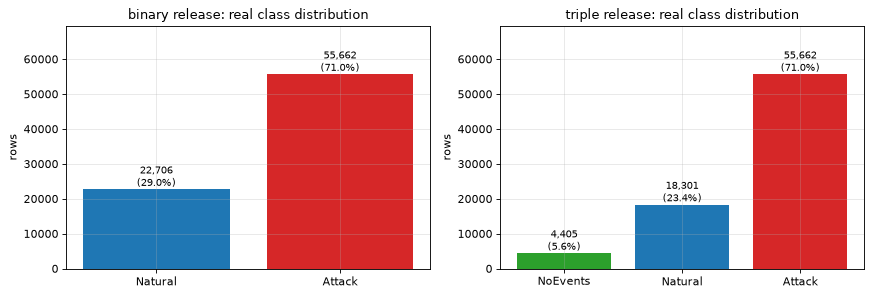

In [5]:
b = TAB["binary"]; t3 = TAB["triple"]
print("BINARY  X shape (rows, features):", b["X"].shape, "| y shape:", b["y"].shape)
print("number of source files:", len(b["files"]), "->", b["files"])
print(f"{len(b['feat'])} feature names. First 12:", b["feat"][:12])
print("last 12:", b["feat"][-12:])
groups = pd.Series(b["feat"]).str.extract(r"^(R\d+|control_panel|snort)", expand=False).fillna("other").value_counts()
print("feature groups (prefix -> #columns):", groups.to_dict())
print("original labels (raw, before dedup):", b["raw_counts"])
print("after dedup:", {b["label_names"][k]: int(v) for k, v in zip(*np.unique(b["y"], return_counts=True))})
print("\nTHREE-CLASS  X shape:", t3["X"].shape, "| original labels (raw):", t3["raw_counts"])
print("after dedup:", {t3["label_names"][k]: int(v) for k, v in zip(*np.unique(t3["y"], return_counts=True))})
print("missing (NaN after inf->NaN) cells in the binary table:", int(np.isnan(b["X"]).sum()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
cols = {"Natural": "tab:blue", "Attack": "tab:red", "NoEvents": "tab:green"}
for a, (name, tab) in zip(ax, TAB.items()):
    vals, cnt = np.unique(tab["y"], return_counts=True)
    names = [tab["label_names"][v] for v in vals]
    bars = a.bar(names, cnt, color=[cols[n] for n in names])
    for bar_, c_ in zip(bars, cnt):
        a.text(bar_.get_x() + bar_.get_width() / 2, c_, f"{c_:,}\n({c_ / cnt.sum():.1%})", ha="center", va="bottom", fontsize=9)
    a.set_title(f"{name} release: real class distribution"); a.set_ylabel("rows"); a.set_ylim(0, cnt.max() * 1.25)
plt.tight_layout(); plt.show()

The paper works with a **random sample of 2,000 rows** that is split 80/20. We draw the sample once (seeded), split it with stratification and fit every preprocessing step on the training part only: the sign-preserving `log1p` of skewed or very large columns, upper clipping at the 99th percentile, mean imputation, standardisation, PCA keeping 95 % of the variance and min-max scaling to [0, 1] (test rows are clipped to that interval). The classes of the sample are shown, then the scatter plots of real rows.

In [6]:
class Prep:
    # log1p of skewed/large columns -> upper clip -> mean impute -> StandardScaler -> PCA(95 %) -> MinMax [0, 1].
    # Every statistic is computed on the TRAINING rows only (CHOICE: the paper fits before splitting, or does not say).
    def __init__(self, Xtr, var=PCA_VARIANCE, seed=SEED):
        sk = np.array([skew(Xtr[~np.isnan(Xtr[:, j]), j]) if np.nanstd(Xtr[:, j]) > 0 else 0.0 for j in range(Xtr.shape[1])])
        big = np.nanmax(np.abs(Xtr), axis=0) > BIG_T
        self.cols = np.where((np.abs(np.nan_to_num(sk)) > SKEW_T) | big)[0]            # columns that get log1p
        Z = self._log(Xtr)
        self.upper = np.nanpercentile(Z, CLIP_Q, axis=0)                              # upper clipping threshold
        Z = np.minimum(Z, self.upper)
        self.mean = np.nanmean(Z, axis=0)
        Z = np.where(np.isnan(Z), self.mean, Z)
        self.sc = StandardScaler().fit(Z)
        self.pca = PCA(n_components=var, svd_solver="full", random_state=seed).fit(self.sc.transform(Z))
        P = self.pca.transform(self.sc.transform(Z))
        self.mm = MinMaxScaler((0.0, 1.0)).fit(P)
    def _log(self, X):
        Z = X.copy()
        Z[:, self.cols] = np.sign(Z[:, self.cols]) * np.log1p(np.abs(Z[:, self.cols]))   # CHOICE: sign-preserving log1p
        return Z
    def pca_space(self, X):                       # raw PCA coordinates
        Z = np.minimum(self._log(X), self.upper)
        Z = np.where(np.isnan(Z), self.mean, Z)
        return self.pca.transform(self.sc.transform(Z))
    def angles(self, P):                          # PCA coordinates scaled to [0, 1] (test values clipped)
        return np.clip(self.mm.transform(P), 0.0, 1.0)

def sample_and_split(tab, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = np.sort(rng.choice(len(tab["y"]), size=SAMPLE_N, replace=False))             # CHOICE: plain random sample
    tr, te = train_test_split(idx, test_size=TEST_SIZE, stratify=tab["y"][idx], random_state=seed)
    return np.sort(tr), np.sort(te)

# main experiment: binary release
tr_b, te_b = sample_and_split(b)
Xtr_raw, ytr, Xte_raw, yte = b["X"][tr_b], b["y"][tr_b], b["X"][te_b], b["y"][te_b]
PB = Prep(Xtr_raw)
Ptr, Pte = PB.pca_space(Xtr_raw), PB.pca_space(Xte_raw)       # raw PCA coordinates
Atr, Ate = PB.angles(Ptr), PB.angles(Pte)                     # in [0, 1]
N_COMP = Ptr.shape[1]; N_BLOCKS = N_COMP // N_QUBITS
print(f"sample {SAMPLE_N}: train {len(tr_b)} / test {len(te_b)} | attack share train {ytr.mean():.3f}, test {yte.mean():.3f}")
print(f"log1p applied to {len(PB.cols)} of {Xtr_raw.shape[1]} columns | PCA keeps {N_COMP} components "
      f"({PB.pca.explained_variance_ratio_.sum():.3f} of the variance) -> {N_BLOCKS} complete blocks of {N_QUBITS} (+{N_COMP % N_QUBITS} dropped)")
print("explained variance ratio of the first 8 components:", np.round(PB.pca.explained_variance_ratio_[:8], 3))
print("angle range of the training data:", Atr.min().round(3), "to", Atr.max().round(3), "| test (clipped):", Ate.min().round(3), "to", Ate.max().round(3))
assert np.all((Ate >= 0) & (Ate <= 1)) and np.all((Atr >= 0) & (Atr <= 1))
print("majority-class accuracy of the test split (predict 'Attack' always):", round(float((yte == 1).mean()), 4))

sample 2000: train 1600 / test 400 | attack share train 0.698, test 0.698
log1p applied to 65 of 128 columns | PCA keeps 32 components (0.952 of the variance) -> 8 complete blocks of 4 (+0 dropped)
explained variance ratio of the first 8 components: [0.14  0.123 0.106 0.078 0.073 0.066 0.037 0.034]
angle range of the training data: 0.0 to 1.0 | test (clipped): 0.0 to 1.0
majority-class accuracy of the test split (predict 'Attack' always): 0.6975


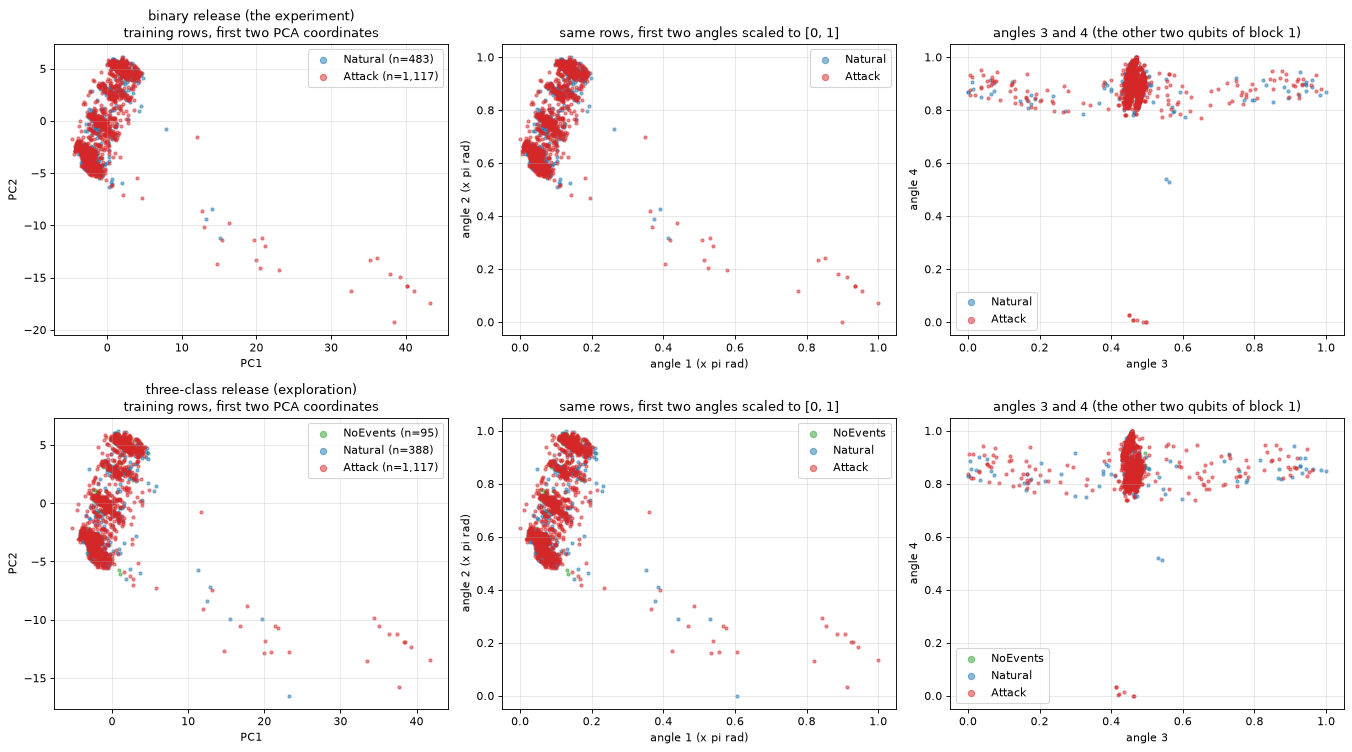

Reading: Natural and Attack rows overlap strongly in the first four components of a 2,000-row sample, so a classifier that sees only block 1 has little more than the class prior to work with. This is the data the paper's 72 % was obtained on.


In [7]:
# Scatter plots of REAL rows coloured by ground-truth label. Binary (the experiment) and three-class (exploration only):
# raw PCA coordinates fitted on the training split, then the same coordinates scaled to [0, 1] (the circuit input angles).
tr_t, te_t = sample_and_split(t3)
P3 = Prep(t3["X"][tr_t])
Z3 = P3.pca_space(t3["X"][tr_t]); A3 = P3.angles(Z3); y3 = t3["y"][tr_t]
pal2 = {0: ("Natural", "tab:blue"), 1: ("Attack", "tab:red")}
pal3 = {0: ("NoEvents", "tab:green"), 1: ("Natural", "tab:blue"), 2: ("Attack", "tab:red")}
fig, ax = plt.subplots(2, 3, figsize=(17, 9.5))
for row, (Zp, Ap, yy, pal, ttl) in enumerate([(Ptr, Atr, ytr, pal2, "binary release (the experiment)"),
                                               (Z3, A3, y3, pal3, "three-class release (exploration)")]):
    for k, (nm, c) in pal.items():
        m = yy == k
        ax[row, 0].scatter(Zp[m, 0], Zp[m, 1], s=8, alpha=0.5, c=c, label=f"{nm} (n={m.sum():,})")
        ax[row, 1].scatter(Ap[m, 0], Ap[m, 1], s=8, alpha=0.5, c=c, label=nm)
        ax[row, 2].scatter(Ap[m, 2], Ap[m, 3], s=8, alpha=0.5, c=c, label=nm)
    ax[row, 0].set_title(f"{ttl}\ntraining rows, first two PCA coordinates"); ax[row, 0].set_xlabel("PC1"); ax[row, 0].set_ylabel("PC2"); ax[row, 0].legend(markerscale=2)
    ax[row, 1].set_title("same rows, first two angles scaled to [0, 1]"); ax[row, 1].set_xlabel("angle 1 (x pi rad)"); ax[row, 1].set_ylabel("angle 2 (x pi rad)"); ax[row, 1].legend(markerscale=2)
    ax[row, 2].set_title("angles 3 and 4 (the other two qubits of block 1)"); ax[row, 2].set_xlabel("angle 3"); ax[row, 2].set_ylabel("angle 4"); ax[row, 2].legend(markerscale=2)
plt.tight_layout(); plt.show()
print("Reading: Natural and Attack rows overlap strongly in the first four components of a 2,000-row sample, so a classifier that sees only "
      "block 1 has little more than the class prior to work with. This is the data the paper's 72 % was obtained on.")

## 4. Quantum Circuit Architecture

Two gate-based quantum models are executed, both on 4 qubits (one qubit per feature of a block) with exact statevectors on PennyLane's `default.qubit`:

1. **QAE-QCNN encoder.** `RY(pi x_i)` loading of the four features of a block, followed by 6 layers of `qml.RandomLayers` (random single-qubit rotations and CNOTs, 4 rotations per layer), then the Pauli-Z expectation of every qubit. The weights are drawn once from a seeded generator and **are not trained** (`# CHOICE:`; the paper only says "random layers"). The symbolic decoder is `1 - z`. *Assumptions where the paper is silent:* the loading angle is `pi x` for `x` in [0, 1]; 4 rotations per random layer; PennyLane's default rotation set (`RX`, `RY`, `RZ`), CNOT as the entangling gate and ratio 0.3 between entangling and rotation gates.
2. **QAE-QRNN.** `AngleEmbedding(rotation="Y")` of `pi (1 - z) / 2`, a trainable encoder (`RX`, `RY`, `RZ` on each qubit, then CNOTs on the adjacent pairs 0-1, 1-2, 2-3) and a trainable mirrored decoder (`RX`, `RY`, `RZ` on each qubit), Pauli-Z read-out. *Assumption:* no CNOT after the decoder rotations, since the paper lists only rotations for the decoder; the read-out is the reconstruction `(1 - z_out) / 2`.

Below we draw the QNodes that are actually run (decomposed to device gates, with real rows as input), print qubit count, depth and trainable-parameter count, and assert that the `TorchLayer` used for training computes exactly the same function as the drawn QNode.

demo input = angles of the first real training row (block 1): [0.097 0.752 0.469 1.   ]


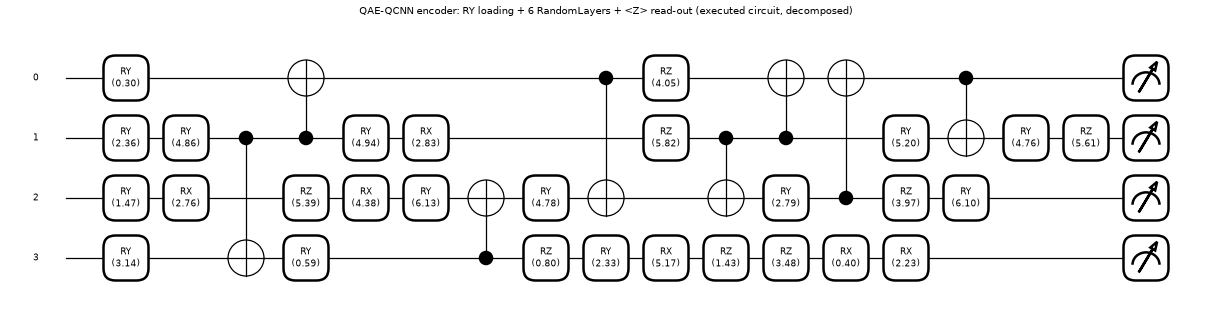

QCNN encoder: qubits=4, depth=14, gates=36, trainable parameters=0 (24 fixed random rotation angles; the paper does not train them)


In [8]:
n = N_QUBITS
dev = qml.device("default.qubit", wires=n)
# CHOICE: fixed random weights of the QCNN encoder (6 layers x 4 rotations), seeded
QCNN_W = np.random.default_rng(SEED).uniform(0, 2 * np.pi, size=qml.RandomLayers.shape(QCNN_LAYERS, n))

@qml.qnode(dev, interface="torch")
def qcnn_qnode(x, weights):
    qml.AngleEmbedding(np.pi * x, wires=range(n), rotation="Y")                      # RY loading of a block
    qml.RandomLayers(weights, wires=range(n), ratio_imprim=0.3, imprimitive=qml.CNOT, seed=SEED)
    return [qml.expval(qml.PauliZ(i)) for i in range(n)]

@qml.qnode(dev, interface="torch")
def qrnn_qnode(inputs, enc, dec):
    qml.AngleEmbedding(inputs, wires=range(n), rotation="Y")                         # inputs already in radians
    for i in range(n):                                                                # encoder rotations
        qml.RX(enc[i, 0], wires=i); qml.RY(enc[i, 1], wires=i); qml.RZ(enc[i, 2], wires=i)
    for i in range(n - 1):                                                            # adjacent-qubit entanglement
        qml.CNOT(wires=[i, i + 1])
    for i in range(n):                                                                # decoder rotations
        qml.RX(dec[i, 0], wires=i); qml.RY(dec[i, 1], wires=i); qml.RZ(dec[i, 2], wires=i)
    return [qml.expval(qml.PauliZ(i)) for i in range(n)]

def circuit_stats(qn, *args):
    sp = qml.specs(qn, level="device")(*args)
    return int(sp.resources.depth), int(sp.resources.num_gates), int(sp.num_device_wires)

x_demo = torch.tensor(Atr[0, :n], dtype=torch.float64)                                # first real training row, block 1
w_qcnn = torch.tensor(QCNN_W, dtype=torch.float64)
print("demo input = angles of the first real training row (block 1):", np.round(x_demo.numpy(), 3))

fig, ax = qml.draw_mpl(qcnn_qnode, decimals=2, fontsize=11, level="device")(x_demo, w_qcnn)
fig.set_dpi(60); fig.suptitle("QAE-QCNN encoder: RY loading + 6 RandomLayers + <Z> read-out (executed circuit, decomposed)", y=1.04)
plt.show()
d, g, q = circuit_stats(qcnn_qnode, x_demo, w_qcnn)
print(f"QCNN encoder: qubits={q}, depth={d}, gates={g}, trainable parameters=0 ({QCNN_W.size} fixed random rotation angles; the paper does not train them)")

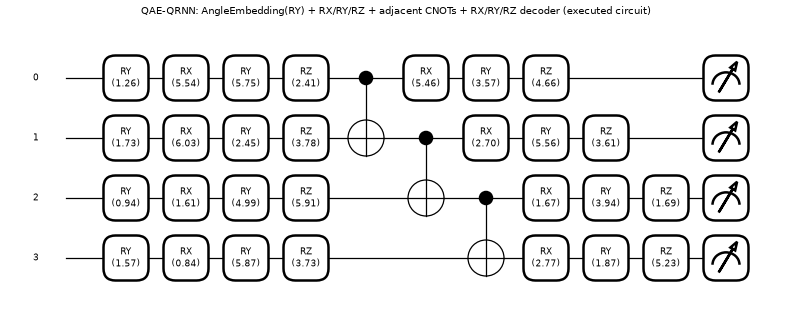

QRNN: qubits=4, depth=10, gates=31, trainable parameters=24 (encoder 12 + decoder 12)


assert passed: TorchLayer(qrnn_qnode) reproduces the drawn QNode on 5 real rows (max abs diff 2.20e-07).
assert passed: batched (broadcast) QCNN evaluation == row-by-row evaluation.
Note: both stages keep 4 qubits in and 4 qubits out; there is no trash qubit or bottleneck, so this 'autoencoder' does not compress.


In [9]:
# QRNN: the QNode that the TorchLayer wraps. Drawn with the same weights that the layer holds.
weight_shapes = {"enc": (n, 3), "dec": (n, 3)}
qrnn_layer_demo = qml.qnn.TorchLayer(qrnn_qnode, weight_shapes)
enc_w, dec_w = qrnn_layer_demo.enc.detach().double(), qrnn_layer_demo.dec.detach().double()
inp_demo = torch.tensor(np.pi * (1.0 - np.array([0.2, -0.1, 0.4, 0.0])) / 2, dtype=torch.float64)   # an example decoded QCNN output
fig, ax = qml.draw_mpl(qrnn_qnode, decimals=2, fontsize=11, level="device")(inp_demo, enc_w, dec_w)
fig.set_dpi(60); fig.suptitle("QAE-QRNN: AngleEmbedding(RY) + RX/RY/RZ + adjacent CNOTs + RX/RY/RZ decoder (executed circuit)", y=1.04)
plt.show()
d, g, q = circuit_stats(qrnn_qnode, inp_demo, enc_w, dec_w)
n_par = enc_w.numel() + dec_w.numel()
print(f"QRNN: qubits={q}, depth={d}, gates={g}, trainable parameters={n_par} (encoder {enc_w.numel()} + decoder {dec_w.numel()})")

# Equivalence: the TorchLayer used in training == the QNode drawn above, for a batch of real decoded QCNN outputs.
Zq = np.stack([np.asarray(qcnn_qnode(torch.tensor(Atr[i, :n], dtype=torch.float64), w_qcnn)) for i in range(5)])
batch_in = torch.tensor(np.pi * (1.0 - Zq) / 2, dtype=torch.float64)
out_layer = qrnn_layer_demo(batch_in.float()).detach().double().numpy()
out_qnode = np.stack([np.asarray(qrnn_qnode(batch_in[i], enc_w, dec_w)) for i in range(5)])
assert np.allclose(out_layer, out_qnode, atol=1e-5), np.abs(out_layer - out_qnode).max()
print("assert passed: TorchLayer(qrnn_qnode) reproduces the drawn QNode on 5 real rows (max abs diff "
      f"{np.abs(out_layer - out_qnode).max():.2e}).")
# the QCNN features of a batch computed through broadcasting equal the row-by-row QNode values
Zb_ = np.asarray(qcnn_qnode(torch.tensor(Atr[:5, :n], dtype=torch.float64), w_qcnn)).T
assert np.allclose(Zb_, Zq, atol=1e-9)
print("assert passed: batched (broadcast) QCNN evaluation == row-by-row evaluation.")
print("Note: both stages keep 4 qubits in and 4 qubits out; there is no trash qubit or bottleneck, so this 'autoencoder' does not compress.")

## 5. The QAE-QCNN stage on the whole sample

The QCNN encoder has fixed weights, so it is a deterministic feature transformation. It is applied once to every block of every row (broadcasting over the batch), the decoder `1 - z` is applied, and the result is stored. The first four columns are block 1, the only input of the main experiment. The scatter plot shows whether the quantum transformation changes the class structure.

QCNN-decoded features: train (1600, 32), test (400, 32), computed in 4.5 s; values in [0.073, 1.622]


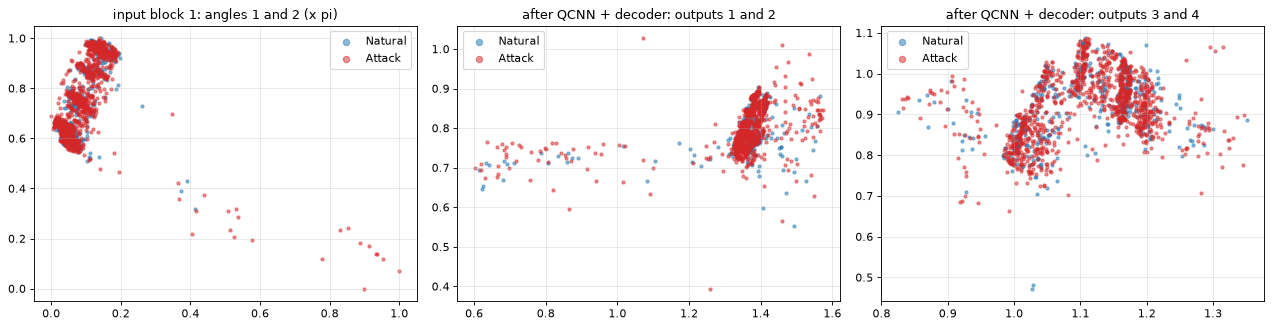

In [10]:
def qcnn_decode(A, chunk=4000):
    # A: (rows, 4*blocks) in [0, 1]. Returns the decoded QCNN output 1 - <Z>, same shape (CHOICE: decoder = 1 - z).
    rows, cols = A.shape
    blocks = A[:, : (cols // n) * n].reshape(-1, n)
    out = np.empty_like(blocks)
    for s in range(0, len(blocks), chunk):
        out[s:s + chunk] = 1.0 - np.asarray(qcnn_qnode(torch.tensor(blocks[s:s + chunk], dtype=torch.float64), w_qcnn)).T
    return out.reshape(rows, -1)

t0 = time.time()
D_tr, D_te = qcnn_decode(Atr), qcnn_decode(Ate)               # all complete blocks
print(f"QCNN-decoded features: train {D_tr.shape}, test {D_te.shape}, computed in {time.time() - t0:.1f} s; values in [{D_tr.min():.3f}, {D_tr.max():.3f}]")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for k, (nm, c) in pal2.items():
    m = ytr == k
    ax[0].scatter(Atr[m, 0], Atr[m, 1], s=8, alpha=0.5, c=c, label=nm)
    ax[1].scatter(D_tr[m, 0], D_tr[m, 1], s=8, alpha=0.5, c=c, label=nm)
    ax[2].scatter(D_tr[m, 2], D_tr[m, 3], s=8, alpha=0.5, c=c, label=nm)
ax[0].set_title("input block 1: angles 1 and 2 (x pi)"); ax[1].set_title("after QCNN + decoder: outputs 1 and 2"); ax[2].set_title("after QCNN + decoder: outputs 3 and 4")
for a in ax: a.legend(markerscale=2)
plt.tight_layout(); plt.show()

## 6. The hybrid quantum-classical classifier and the classical baseline

* **Hybrid.** Fixed QCNN output `d = 1 - z` (4 values per block) -> trainable QRNN `TorchLayer` (24 parameters, shared by all blocks) -> reconstruction `(1 - z_out) / 2` -> classifier head `Linear(4, 16) - ReLU - Linear(16, 2)`. Loss = cross-entropy of the head + `MSE(reconstruction, input block)` (the QAE reconstruction error). Adam, learning rate 1e-3, as in the paper.
* **Classical.** The same head applied directly to the input block. Cross-entropy only, Adam, learning rate 1e-2, as in the paper.

`train_model` returns, for every epoch, the training loss and accuracy and the test loss (cross-entropy) and accuracy, which is what Figure 1 of the paper plots. The test split is evaluated after every epoch for plotting only; nothing is selected on it (no early stopping, the last epoch is reported).

In [11]:
class HybridQAE(nn.Module):
    def __init__(self, n_blocks):
        super().__init__()
        self.nb = n_blocks
        self.qrnn = qml.qnn.TorchLayer(qrnn_qnode, weight_shapes)                   # trainable QRNN (24 parameters)
        self.head = nn.Sequential(nn.Linear(n * n_blocks, HIDDEN), nn.ReLU(), nn.Linear(HIDDEN, 2))
    def forward(self, d):                                                           # d: decoded QCNN output, (B, 4*nb) in [0, 2]
        B = d.shape[0]
        ang = (np.pi * d / 2).reshape(B * self.nb, n)                               # CHOICE: angles in [0, pi]
        z = self.qrnn(ang).reshape(B, self.nb * n)
        recon = (1.0 - z) / 2.0                                                     # QAE reconstruction in [0, 1]
        return self.head(recon), recon

class ClassicalNet(nn.Module):
    def __init__(self, n_blocks):
        super().__init__()
        self.head = nn.Sequential(nn.Linear(n * n_blocks, HIDDEN), nn.ReLU(), nn.Linear(HIDDEN, 2))
    def forward(self, x):
        return self.head(x), None

def train_model(model, Xin, Xtarget, y_tr, Xin_te, y_te, lr, epochs, seed, use_recon):
    # Adam, mini-batches, shuffling every epoch; returns per-epoch curves (train/test loss and accuracy).
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    ce, mse = nn.CrossEntropyLoss(), nn.MSELoss()
    Xi, Xt, Yt = torch.tensor(Xin, dtype=torch.float32), torch.tensor(Xtarget, dtype=torch.float32), torch.tensor(y_tr)
    Xv, Yv = torch.tensor(Xin_te, dtype=torch.float32), torch.tensor(y_te)
    hist = dict(train_loss=[], train_acc=[], test_loss=[], test_acc=[])
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xi), generator=g); tl = 0.0; ta = 0
        for s in range(0, len(Xi), BATCH):
            idx = perm[s:s + BATCH]
            logits, recon = model(Xi[idx])
            loss = ce(logits, Yt[idx])
            if use_recon:
                loss = loss + MSE_WEIGHT * mse(recon, Xt[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            tl += float(loss) * len(idx); ta += int((logits.argmax(1) == Yt[idx]).sum())
        model.eval()
        with torch.no_grad():
            lg, _ = model(Xv)
            hist["test_loss"].append(float(ce(lg, Yv))); hist["test_acc"].append(float((lg.argmax(1) == Yv).float().mean()))
        hist["train_loss"].append(tl / len(Xi)); hist["train_acc"].append(ta / len(Xi))
    return hist, model

## 7. Training: the main experiment (first block, 4 features)

The paper's setting: the classifier sees four features. The hybrid model receives the QCNN output of block 1, the classical model block 1 itself. Each model is trained from `N_SEEDS` initialisations on the same split and the curves are averaged.

In [12]:
nb1 = 1
X1_tr, X1_te = Atr[:, :n], Ate[:, :n]                    # block 1 angles in [0, 1] (the classical input and the QAE target)
D1_tr, D1_te = D_tr[:, :n], D_te[:, :n]                  # decoded QCNN output of block 1 (the hybrid input)
RES = {"hybrid": [], "classical": []}
MODELS = {}
t0 = time.time()
for s in range(N_SEEDS):
    seed = SEED + s
    torch.manual_seed(seed)
    mh = HybridQAE(nb1)
    h, mh = train_model(mh, D1_tr, X1_tr, ytr, D1_te, yte, LR_QUANTUM, EPOCHS, seed, use_recon=True)
    RES["hybrid"].append(h); MODELS[("hybrid", s)] = mh
    torch.manual_seed(seed)
    mc = ClassicalNet(nb1)
    h, mc = train_model(mc, X1_tr, X1_tr, ytr, X1_te, yte, LR_CLASSICAL, EPOCHS, seed, use_recon=False)
    RES["classical"].append(h); MODELS[("classical", s)] = mc
    print(f"seed {seed}: hybrid final test acc {RES['hybrid'][-1]['test_acc'][-1]:.3f} loss {RES['hybrid'][-1]['test_loss'][-1]:.3f} | "
          f"classical final test acc {RES['classical'][-1]['test_acc'][-1]:.3f} loss {RES['classical'][-1]['test_loss'][-1]:.3f} "
          f"| elapsed {time.time() - t0:.0f} s")
T_MAIN = time.time() - t0

seed 42: hybrid final test acc 0.697 loss 0.613 | classical final test acc 0.697 loss 0.613 | elapsed 522 s


seed 43: hybrid final test acc 0.697 loss 0.614 | classical final test acc 0.697 loss 0.608 | elapsed 1111 s


seed 44: hybrid final test acc 0.697 loss 0.613 | classical final test acc 0.697 loss 0.611 | elapsed 1690 s


seed 45: hybrid final test acc 0.697 loss 0.613 | classical final test acc 0.697 loss 0.611 | elapsed 2304 s


seed 46: hybrid final test acc 0.697 loss 0.613 | classical final test acc 0.697 loss 0.610 | elapsed 2853 s


## 8. Re-drawing Figure 1 of the paper (test accuracy and test loss per epoch)

Mean over seeds with a +/- 1 standard deviation band. The dotted horizontal line is the majority-class accuracy of the test split (what a model that always answers "Attack" scores), a reference the paper does not show.

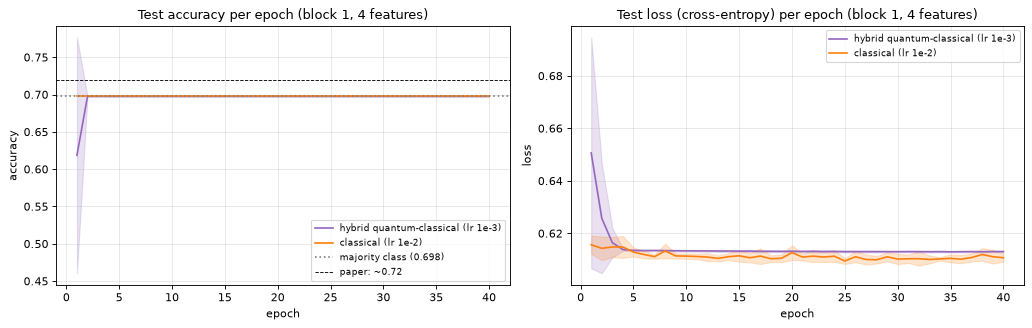

,experiment,model,final_train_acc,final_test_acc,binom_95CI_of_mean,final_test_loss
0,block 1 (4 features),hybrid,0.698 +/- 0.000,0.697 +/- 0.000,+/- 0.045,0.613 +/- 0.000
1,block 1 (4 features),classical,0.698 +/- 0.000,0.697 +/- 0.000,+/- 0.045,0.611 +/- 0.002


In [13]:
def plot_fig1(RES_, title_suffix=""):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    ep = np.arange(1, len(RES_["hybrid"][0]["test_acc"]) + 1)
    for mode, c, lab in (("hybrid", "tab:purple", "hybrid quantum-classical (lr 1e-3)"), ("classical", "tab:orange", "classical (lr 1e-2)")):
        for ai, key in enumerate(("test_acc", "test_loss")):
            A = np.array([h[key] for h in RES_[mode]]); m, sd = A.mean(0), A.std(0)
            ax[ai].plot(ep, m, color=c, label=lab); ax[ai].fill_between(ep, m - sd, m + sd, color=c, alpha=0.2)
    maj = float((yte == 1).mean())
    ax[0].axhline(maj, color="gray", ls=":", label=f"majority class ({maj:.3f})"); ax[0].axhline(0.72, color="k", ls="--", lw=0.8, label="paper: ~0.72")
    ax[0].set_title("Test accuracy per epoch" + title_suffix); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("accuracy"); ax[0].legend(fontsize=8)
    ax[1].set_title("Test loss (cross-entropy) per epoch" + title_suffix); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("loss"); ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()

RES_ = RES
plot_fig1(RES, " (block 1, 4 features)")
def summarise(RES_, name):
    rows = []
    for mode in ("hybrid", "classical"):
        acc = np.array([h["test_acc"][-1] for h in RES_[mode]]); loss = np.array([h["test_loss"][-1] for h in RES_[mode]])
        tra = np.array([h["train_acc"][-1] for h in RES_[mode]])
        p = acc.mean(); ci = 1.96 * math.sqrt(p * (1 - p) / len(yte))
        rows.append(dict(experiment=name, model=mode, final_train_acc=f"{tra.mean():.3f} +/- {tra.std():.3f}", final_test_acc=f"{acc.mean():.3f} +/- {acc.std():.3f}",
                         binom_95CI_of_mean=f"+/- {ci:.3f}", final_test_loss=f"{loss.mean():.3f} +/- {loss.std():.3f}"))
    return pd.DataFrame(rows)
SUM_MAIN = summarise(RES, "block 1 (4 features)")
display(SUM_MAIN)

## 9. Metrics and confusion matrices

Final-epoch models of seed 0, attack as the positive class. The paper reports only accuracy and loss; precision, recall and F1 show *what* a roughly 72 % accuracy means on this imbalanced data.

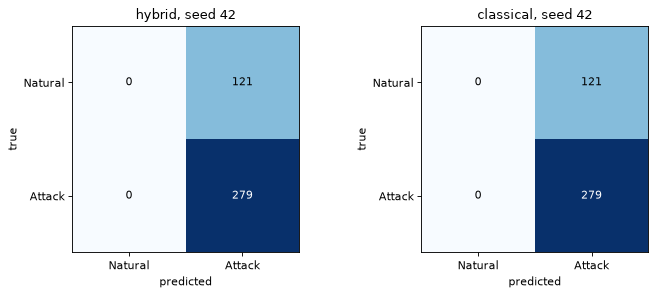

,model,accuracy,precision,recall,f1,share_predicted_attack
0,hybrid,0.698,0.698,1.0,0.822,1.0
1,classical,0.698,0.698,1.0,0.822,1.0


In [14]:
def predict(mode, s, Din, Xin):
    m = MODELS[(mode, s)]; m.eval()
    with torch.no_grad():
        lg, _ = m(torch.tensor(Din if mode == "hybrid" else Xin, dtype=torch.float32))
    return lg.argmax(1).numpy()

fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
rows = []
for a, mode in zip(ax, ("hybrid", "classical")):
    yp = predict(mode, 0, D1_te, X1_te)
    cm = confusion_matrix(yte, yp, labels=[0, 1])
    a.imshow(cm, cmap="Blues"); a.set_title(f"{mode}, seed {SEED}"); a.set_xlabel("predicted"); a.set_ylabel("true")
    a.set_xticks([0, 1]); a.set_xticklabels(["Natural", "Attack"]); a.set_yticks([0, 1]); a.set_yticklabels(["Natural", "Attack"]); a.grid(False)
    for (i, j), v in np.ndenumerate(cm):
        a.text(j, i, int(v), ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
    rows.append(dict(model=mode, accuracy=accuracy_score(yte, yp), precision=precision_score(yte, yp, zero_division=0),
                     recall=recall_score(yte, yp, zero_division=0), f1=f1_score(yte, yp, zero_division=0),
                     share_predicted_attack=float(yp.mean())))
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).round(3))

## 10. Sanity baselines on the same split (not in the paper)

What does a 72 % accuracy mean? Trivial and standard classical models on exactly the same split: the majority class, a random forest and an RBF-SVM on the **same four block-1 features**, on **all PCA components**, and on **all 128 raw (standardised) features**. These models are not tuned (`# CHOICE:` defaults, `C=1`, 200 trees).

In [15]:
Xraw_tr = np.where(np.isnan(Xtr_raw), np.nanmean(Xtr_raw, axis=0), Xtr_raw); Xraw_te = np.where(np.isnan(Xte_raw), np.nanmean(Xtr_raw, axis=0), Xte_raw)
scr = StandardScaler().fit(Xraw_tr); XR_tr, XR_te = scr.transform(Xraw_tr), scr.transform(Xraw_te)
variants = {"block 1 angles (4 features)": (X1_tr, X1_te), "QCNN-decoded block 1 (4 features)": (D1_tr, D1_te),
            f"all PCA angles ({N_COMP} features)": (Atr, Ate), "all 128 raw features (standardised)": (XR_tr, XR_te)}
rows = [dict(input="-", model="majority class", test_acc=float(DummyClassifier(strategy="most_frequent").fit(X1_tr, ytr).score(X1_te, yte)), f1_attack=np.nan)]
for nm, (A_, B_) in variants.items():
    for mname, mdl in (("RandomForest", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=N_THREADS)), ("SVC rbf", SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED))):
        yp = mdl.fit(A_, ytr).predict(B_)
        rows.append(dict(input=nm, model=mname, test_acc=accuracy_score(yte, yp), f1_attack=f1_score(yte, yp)))
BASE = pd.DataFrame(rows)
display(BASE.round(4))

,input,model,test_acc,f1_attack
0,-,majority class,0.6975,NaN
1,block 1 angles (4 features),RandomForest,0.6900,0.8006
2,block 1 angles (4 features),SVC rbf,0.6975,0.8218
3,QCNN-decoded block 1 (4 features),RandomForest,0.6900,0.7994
4,QCNN-decoded block 1 (4 features),SVC rbf,0.6975,0.8218
5,all PCA angles (32 features),RandomForest,0.6825,0.7935
6,all PCA angles (32 features),SVC rbf,0.6975,0.8218
7,all 128 raw features (standardised),RandomForest,0.7000,0.8039
8,all 128 raw features (standardised),SVC rbf,0.6825,0.8096


## 11. Extension: the same circuits on every block (not in the paper's numbers)

The paper says the transformed data are "divided into fixed-size blocks of 4 features" but reports a classifier on four features. Here the same QCNN (fixed) and the same QRNN (24 shared parameters) are applied to every complete block and the reconstructions are concatenated before the classifier head; the classical model sees all block features. This shows what the stacked autoencoder does when it is given the information that the PCA retained.

seed 42: hybrid 0.697 | classical 0.697 | elapsed 808 s


seed 43: hybrid 0.697 | classical 0.697 | elapsed 1404 s


seed 44: hybrid 0.697 | classical 0.697 | elapsed 1828 s


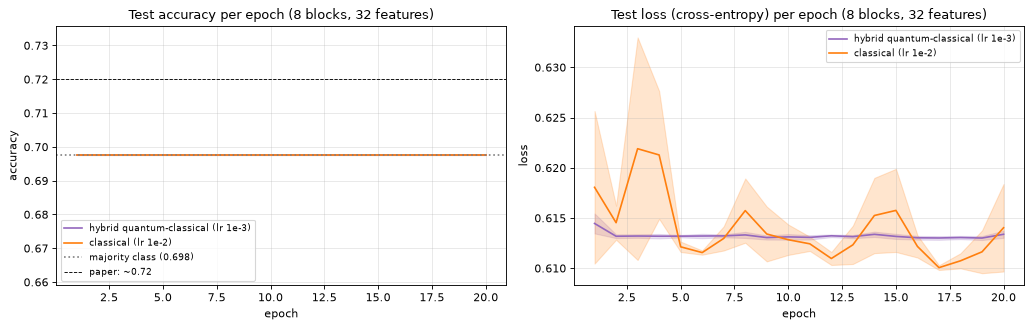

,experiment,model,final_train_acc,final_test_acc,binom_95CI_of_mean,final_test_loss
0,all 8 blocks (32 features),hybrid,0.698 +/- 0.000,0.697 +/- 0.000,+/- 0.045,0.613 +/- 0.000
1,all 8 blocks (32 features),classical,0.698 +/- 0.000,0.697 +/- 0.000,+/- 0.045,0.614 +/- 0.004


In [16]:
RES_ALL = {"hybrid": [], "classical": []}
t0 = time.time()
for s in range(N_SEEDS_ALL):
    seed = SEED + s
    torch.manual_seed(seed)
    mh = HybridQAE(N_BLOCKS)
    h, mh = train_model(mh, D_tr, Atr[:, : N_BLOCKS * n], ytr, D_te, yte, LR_QUANTUM, EPOCHS_ALL, seed, use_recon=True)
    RES_ALL["hybrid"].append(h)
    torch.manual_seed(seed)
    mc = ClassicalNet(N_BLOCKS)
    h, mc = train_model(mc, Atr[:, : N_BLOCKS * n], Atr[:, : N_BLOCKS * n], ytr, Ate[:, : N_BLOCKS * n], yte, LR_CLASSICAL, EPOCHS_ALL, seed, use_recon=False)
    RES_ALL["classical"].append(h)
    print(f"seed {seed}: hybrid {RES_ALL['hybrid'][-1]['test_acc'][-1]:.3f} | classical {RES_ALL['classical'][-1]['test_acc'][-1]:.3f} | elapsed {time.time() - t0:.0f} s")
T_ALL = time.time() - t0
plot_fig1(RES_ALL, f" ({N_BLOCKS} blocks, {N_BLOCKS * n} features)")
SUM_ALL = summarise(RES_ALL, f"all {N_BLOCKS} blocks ({N_BLOCKS * n} features)")
display(SUM_ALL)

## 12. Side by side with the paper

Verdict rules: a number is *reproduced* when it is within 2 accuracy points of the paper's value; otherwise *not reached* (below) or *exceeded* (above) with the gap. Qualitative claims about curve shapes are turned into explicit, stated tests on the seed-averaged curves of the main experiment. Anything that cannot be tested is marked *cannot be checked*.

In [17]:
Hm = np.array([h["test_acc"] for h in RES["hybrid"]]); Cm = np.array([h["test_acc"] for h in RES["classical"]])
Hl = np.array([h["test_loss"] for h in RES["hybrid"]]); Cl = np.array([h["test_loss"] for h in RES["classical"]])
ha, ca = Hm[:, -1].mean(), Cm[:, -1].mean()
y_all = b["y"]
def num_verdict(x, ref=0.72, tol=0.02):
    return "reproduced" if abs(x - ref) <= tol else ("exceeded" if x > ref else "not reached") + f" ({x - ref:+.3f})"
def mono_down(l):                      # fraction of epoch-to-epoch steps in which the mean loss decreased, and net change
    m = l.mean(0); return float((np.diff(m) < 0).mean()), float(m[-1] - m[0])
fd_h, net_h = mono_down(Hl); fd_c, net_c = mono_down(Cl)
cm_ = Cl.mean(0); degr = float(cm_[-1] - cm_.min())
last = max(3, EPOCHS // 3)
sd_h, sd_c = float(Hm.mean(0)[-last:].std()), float(Cm.mean(0)[-last:].std())
rows = [
 ("C1 hybrid test accuracy ~ 72 %", "about 72 % (Sec. 4.5)", f"{ha:.3f}", num_verdict(ha)),
 ("C1 classical test accuracy ~ 72 %", "about 72 % (Sec. 4.5)", f"{ca:.3f}", num_verdict(ca)),
 ("C2 hybrid comparable to or better than classical", "Conclusion / Sec. 4.5", f"hybrid - classical = {ha - ca:+.3f}",
  "reproduced" if ha - ca >= -0.02 else f"not reached ({ha - ca:+.3f})"),
 ("C3 quantum test loss decreases consistently", "Sec. 4.5, Fig. 1", f"loss fell in {fd_h:.0%} of epoch steps; net change {net_h:+.4f}",
  "reproduced" if (fd_h >= 0.7 and net_h < 0) else "not reached"),
 ("C4 classical loss starts lower, then degrades", "Sec. 4.5, Fig. 1", f"classical epoch-1 loss {cm_[0]:.3f} vs hybrid {Hl.mean(0)[0]:.3f}; classical final - min = {degr:+.4f}",
  "reproduced" if (cm_[0] < Hl.mean(0)[0] and degr > 0.01) else "not reached"),
 ("C5 quantum model more stable in late epochs", "Sec. 4.5", f"std of mean test accuracy over last {last} epochs: hybrid {sd_h:.4f}, classical {sd_c:.4f}",
  "reproduced" if sd_h < sd_c - 1e-3 else ("not reached" if sd_h > sd_c + 1e-3 else "cannot be distinguished (both curves are flat)")),
 ("C1* the ~72 % equals the class prior", "implied (not stated); 71 % of rows are attacks", f"majority class of this test split {float((yte == 1).mean()):.3f}; share of attacks in all {len(y_all):,} rows {float(y_all.mean()):.3f}; models {ha:.3f} / {ca:.3f}",
  "consistent: both models sit on the prior" if max(abs(ha - (yte == 1).mean()), abs(ca - (yte == 1).mean())) < 0.02 else "models differ from the prior"),
 ("Quantum advantage / better than classical", "Conclusion (hedged: 'comparable or better')", f"hybrid - classical = {ha - ca:+.3f}; trivial majority = {float((yte == 1).mean()):.3f}",
  "cannot be established: difference within noise" if abs(ha - ca) < 0.03 else "see numbers"),
 ("Hardware / noise results", "none reported (future work)", "-", "cannot be checked"),
]
CMP = pd.DataFrame(rows, columns=["claim", "paper (where)", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 120, "display.width", 250)
display(CMP)
print(f"Majority-class accuracy of the test split: {float((yte == 1).mean()):.3f}. Hybrid {ha:.3f} / classical {ca:.3f} (mean of {N_SEEDS} seeds, last epoch).")
print(f"Total wall-clock of this notebook so far: {(time.time() - T0) / 60:.1f} min  (main experiment {T_MAIN:.0f} s, all-blocks {T_ALL:.0f} s)")

,claim,paper (where),this notebook,verdict
0,C1 hybrid test accuracy ~ 72 %,about 72 % (Sec. 4.5),0.697,not reached (-0.023)
1,C1 classical test accuracy ~ 72 %,about 72 % (Sec. 4.5),0.697,not reached (-0.023)
2,C2 hybrid comparable to or better than classical,Conclusion / Sec. 4.5,hybrid - classical = +0.000,reproduced
3,C3 quantum test loss decreases consistently,"Sec. 4.5, Fig. 1",loss fell in 69% of epoch steps; net change -0.0376,not reached
4,"C4 classical loss starts lower, then degrades","Sec. 4.5, Fig. 1",classical epoch-1 loss 0.616 vs hybrid 0.651; classical final - min = +0.0013,not reached
5,C5 quantum model more stable in late epochs,Sec. 4.5,"std of mean test accuracy over last 13 epochs: hybrid 0.0000, classical 0.0000",cannot be distinguished (both curves are flat)
6,C1* the ~72 % equals the class prior,implied (not stated); 71 % of rows are attacks,"majority class of this test split 0.698; share of attacks in all 78,368 rows 0.710; models 0.697 / 0.697",consistent: both models sit on the prior
7,Quantum advantage / better than classical,Conclusion (hedged: 'comparable or better'),hybrid - classical = +0.000; trivial majority = 0.698,cannot be established: difference within noise
8,Hardware / noise results,none reported (future work),-,cannot be checked


Majority-class accuracy of the test split: 0.698. Hybrid 0.697 / classical 0.697 (mean of 5 seeds, last epoch).
Total wall-clock of this notebook so far: 79.9 min  (main experiment 2853 s, all-blocks 1828 s)


## 13. Reading the paper critically

* **Accuracy equals the class prior.** About 71 % of the pooled binary data are attacks, so a classifier that answers "Attack" for every row scores about 71 %, essentially the 72 % both models reach in the paper. In this notebook the final models of both families answer "Attack" for every test row (recall 1.00, precision equal to the attack share, see the confusion matrices), they score the majority-class accuracy of the split, and random forests and RBF-SVMs on the same inputs, even on all 128 raw features, do no better with 1,600 training rows (section 10). A side check that is not part of this notebook (random forest on raw features, 40,000 random training rows) gave about 0.90 accuracy, so the information is in the data but not in a 2,000-row sample with four features; exercise 1 and 6 below let you repeat it. With four features and 2,000 rows nothing in Figure 1 shows that either model has learned to separate attacks from natural disturbances. The convergence of the two curves to the same value is what one expects from two models that both collapse towards the prior.
* **A single run, a single split, 400 test rows.** One test accuracy has a binomial 95 % half-width of about 4 points here, larger than any gap discussed in the paper. "More stable" and "consistently decreasing" are statements about one curve each.
* **Not an anomaly detector.** The title and abstract speak of anomaly detection, but the model is a *supervised* classifier on labelled attacks and natural events. Nothing is trained on normal data only and no reconstruction-error threshold is used; the QAE reconstruction loss is merely an auxiliary term.
* **The "autoencoder" does not compress and the first stage is not trained.** Four qubits go in and four come out; there is no latent bottleneck or trash qubit, and the QCNN stage (random layers) acts as a fixed random feature map. The classifier head, not the quantum circuit, carries the learning capacity.
* **Different learning rates.** The quantum model uses 1e-3 and the classical one 1e-2; the loss curves therefore differ in speed for a reason unrelated to quantum computing, and "the classical loss degrades" is equally an effect of the larger learning rate.
* **Information bottleneck from the input.** Only the first block (4 of the retained principal components) is used, although the PCA kept far more variance; the extension in section 11 gives both models all blocks.
* **Missing details.** Epochs, batch size, seeds, which dataset variant, the head architecture, whether circuit weights are trained, the clipping threshold, and whether the preprocessing was fitted before splitting are not stated; these are choices in this notebook.
* **Positive points.** The authors are open that this is a proof of concept, the circuits are small and fully specified up to the details listed above, and the motivation (cheap, shallow circuits for edge devices in the grid) is reasonable.

## 14. Exercises

1. **Seeds and splits.** Increase `N_SEEDS` and also vary the data sample (`sample_and_split(b, seed)`); report a mean and a standard deviation over *data* splits. Does the gap between hybrid and classical ever exceed the spread?
2. **Equalise the learning rate.** Train the classical network with `LR_QUANTUM = 1e-3` (and the hybrid with 1e-2). Does the "degradation" of the classical test loss disappear?
3. **Balanced evaluation.** Replace accuracy by balanced accuracy or macro-F1 and re-draw Figure 1. Do the models still look alike?
4. **Train the QCNN.** Make `QCNN_W` a `TorchLayer` weight (24 trainable angles) and compare against the fixed random layers. Is the learning signal in the circuit or in the head?
5. **Real autoencoding.** Rewrite the QRNN stage with 4 data qubits and 2 trash qubits (SWAP-test or reset), train it on `Natural` rows only and use the reconstruction fidelity as an anomaly score with a threshold chosen on a validation split. How does its AUC compare with the supervised head and with the random forest of section 10?
6. **Sample size.** Raise `SAMPLE_N` from 2,000 to 10,000 and 40,000 (the PCA and the QCNN stage scale linearly, the QRNN training time grows with the number of rows) and plot test accuracy of the random forest, the classical head and the hybrid model against the training-set size. At which size do the models leave the class prior?